In [ ]:
%run ./TP2_Base.ipynb

import torch.nn as nn
import torch.optim as optim
import copy

RUN_EXPERIMENTS = False

PyTorch: 2.13.0+cu130
Device: cuda
Dataset size: 10073
Image shape: torch.Size([3, 128, 128])
MOS label: 3.83
Training samples: 8058
Validation samples: 1007
Test samples: 1008
Dimensions des images : torch.Size([32, 3, 128, 128])
Dimensions des labels : torch.Size([32])
Les 5 premiers MOS : tensor([3.6881, 3.6566, 3.0917, 3.5050, 2.2477])


on reprend le CNN milestone 1 pour les tests:

In [2]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.regressor = nn.Linear(32, 1)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        x = self.regressor(x)
        return x.squeeze(1)


model = SimpleCNN().to(device)

print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (regressor): Linear(in_features=32, out_features=1, bias=True)
)



## 3. Training Configuration

We use the same training configuration as in Milestone 1:

- **Loss function:** Mean Squared Error (MSE), since predicting the MOS is a regression task.
- **Optimizer:** Adam, with a learning rate of 0.001.
- **Model:** The same `SimpleCNN` architecture as in Milestone 1.

At this stage, we keep the architecture and optimizer unchanged to study the effect of Early Stopping independently.



### Reproducibility

To ensure a fair comparison between experiments, we use a fixed random seed (`42`).

Before each experiment, we:
- Initialize the CNN with the same random weights.
- Reset the training DataLoader with the same shuffle seed.
- Use the same training and validation datasets.
- Keep the same optimizer and initial learning rate.

This allows us to isolate the effect of each optimization technique.


In [3]:

# ===== REPRODUCIBILITY =====
torch.manual_seed(42)

# Initialize the CNN with fixed random weights
model = SimpleCNN().to(device)

# Recreate the training DataLoader with a fixed shuffle seed
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

# ===== TRAINING CONFIGURATION =====
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)



## 4. Early Stopping

Early Stopping is a technique used to prevent overfitting by stopping training when the validation loss no longer improves.

Instead of training for a fixed number of epochs, we define:

- **Maximum epochs:** 30, the maximum training duration.
- **Patience:** 5, the number of consecutive epochs without validation improvement before stopping.
- **Best validation loss:** The lowest validation MSE observed during training.

We also save the best model weights in memory so that the final model corresponds to the epoch with the lowest validation loss, rather than necessarily the last epoch.

The test set is not used during this process.


In [ ]:
if RUN_EXPERIMENTS:

    # Configuration Early Stopping
    epochs = 30
    patience = 5

    best_val_loss = float("inf")
    best_epoch = 0
    counter = 0
    best_model_state = None

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # ===== ENTRAINEMENT =====
        model.train()
        train_loss = 0.0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            predictions = model(images)
            loss = criterion(predictions, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

        train_loss /= len(train_dataset)
        train_losses.append(train_loss)

        # ===== VALIDATION =====
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                predictions = model(images)
                loss = criterion(predictions, labels)

                val_loss += loss.item() * images.size(0)

        val_loss /= len(val_dataset)
        val_losses.append(val_loss)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train MSE: {train_loss:.4f} | "
            f"Validation MSE: {val_loss:.4f}"
        )

        # ===== EARLY STOPPING =====
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            counter = 0

            # Keep the weights of the best epoch
            best_model_state = copy.deepcopy(model.state_dict())

        else:
            counter += 1

        if counter >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

    # Restore the best model weights
    model.load_state_dict(best_model_state)

    print(f"Best epoch: {best_epoch}")
    print(f"Best validation MSE: {best_val_loss:.4f}")


Epoch 1/30 | Train MSE: 1.0391 | Validation MSE: 0.3602
Epoch 2/30 | Train MSE: 0.2819 | Validation MSE: 0.2922
Epoch 3/30 | Train MSE: 0.2351 | Validation MSE: 0.2422
Epoch 4/30 | Train MSE: 0.2278 | Validation MSE: 0.2487
Epoch 5/30 | Train MSE: 0.2261 | Validation MSE: 0.2382
Epoch 6/30 | Train MSE: 0.2256 | Validation MSE: 0.2370
Epoch 7/30 | Train MSE: 0.2264 | Validation MSE: 0.2362
Epoch 8/30 | Train MSE: 0.2202 | Validation MSE: 0.2462
Epoch 9/30 | Train MSE: 0.2196 | Validation MSE: 0.2367
Epoch 10/30 | Train MSE: 0.2178 | Validation MSE: 0.2408
Epoch 11/30 | Train MSE: 0.2244 | Validation MSE: 0.2518
Epoch 12/30 | Train MSE: 0.2176 | Validation MSE: 0.2357
Epoch 13/30 | Train MSE: 0.2208 | Validation MSE: 0.2427
Epoch 14/30 | Train MSE: 0.2168 | Validation MSE: 0.2401
Epoch 15/30 | Train MSE: 0.2193 | Validation MSE: 0.2400
Epoch 16/30 | Train MSE: 0.2173 | Validation MSE: 0.2337
Epoch 17/30 | Train MSE: 0.2150 | Validation MSE: 0.2378
Epoch 18/30 | Train MSE: 0.2171 | Valida


### Early Stopping Results

The CNN was trained for a maximum of 30 epochs, with an Early Stopping patience of 5.

**Results:**
- Completed epochs: 30
- Best epoch: 27
- Best validation MSE: 0.2267
- Early Stopping triggered: No

The validation MSE fluctuated throughout training, with its lowest value reached at epoch 27.

Early Stopping was not triggered because the patience threshold was not reached before the maximum number of epochs.

However, the best model weights from epoch 27 were restored.

**Conclusion:** In this experiment, the best-checkpoint mechanism was useful, but Early Stopping did not reduce training time.



## 5. Learning Rate Scheduler

After implementing Early Stopping, we now introduce a Learning Rate Scheduler.

We use `ReduceLROnPlateau`, which automatically reduces the learning rate when the validation MSE stops improving.

We combine:
- **Early Stopping:** patience = 5
- **LR Scheduler:** patience = 2, factor = 0.5
- **Initial learning rate:** 0.001

The goal is to determine whether reducing the learning rate can improve validation performance before Early Stopping is triggered.

We keep the original CNN architecture and do not introduce additional regularization yet.


In [ ]:
if RUN_EXPERIMENTS:

    # Save results from Experiment 1
    train_losses_early = train_losses.copy()
    val_losses_early = val_losses.copy()

    # ===== REPRODUCIBILITY =====
    torch.manual_seed(42)

    model = SimpleCNN().to(device)

    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=torch.Generator().manual_seed(42)
    )

    # ===== TRAINING CONFIGURATION =====
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Learning Rate Scheduler
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )


    # Early Stopping configuration
    epochs = 30
    patience = 5
    counter = 0
    best_val_loss = float("inf")
    best_epoch = 0
    best_model_state = None

    train_losses = []
    val_losses = []
    learning_rates = []

    for epoch in range(epochs):

        # ===== TRAINING =====
        model.train()
        train_loss = 0.0

        current_lr = optimizer.param_groups[0]["lr"]
        learning_rates.append(current_lr)

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            predictions = model(images)
            loss = criterion(predictions, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

        train_loss /= len(train_dataset)
        train_losses.append(train_loss)

        # ===== VALIDATION =====
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                predictions = model(images)
                loss = criterion(predictions, labels)

                val_loss += loss.item() * images.size(0)

        val_loss /= len(val_dataset)
        val_losses.append(val_loss)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train MSE: {train_loss:.4f} | "
            f"Validation MSE: {val_loss:.4f} | "
            f"LR: {current_lr:.6f}"
        )

        # ===== SCHEDULER =====
        scheduler.step(val_loss)

        # ===== EARLY STOPPING =====
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            counter = 0
            best_model_state = copy.deepcopy(model.state_dict())
        else:
            counter += 1

        if counter >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

    # Restore best weights
    model.load_state_dict(best_model_state)

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation MSE: {best_val_loss:.4f}")


Epoch 1/30 | Train MSE: 1.0391 | Validation MSE: 0.3602 | LR: 0.001000
Epoch 2/30 | Train MSE: 0.2819 | Validation MSE: 0.2923 | LR: 0.001000
Epoch 3/30 | Train MSE: 0.2351 | Validation MSE: 0.2422 | LR: 0.001000
Epoch 4/30 | Train MSE: 0.2278 | Validation MSE: 0.2487 | LR: 0.001000
Epoch 5/30 | Train MSE: 0.2261 | Validation MSE: 0.2382 | LR: 0.001000
Epoch 6/30 | Train MSE: 0.2256 | Validation MSE: 0.2370 | LR: 0.001000
Epoch 7/30 | Train MSE: 0.2264 | Validation MSE: 0.2362 | LR: 0.001000
Epoch 8/30 | Train MSE: 0.2202 | Validation MSE: 0.2462 | LR: 0.001000
Epoch 9/30 | Train MSE: 0.2196 | Validation MSE: 0.2367 | LR: 0.001000
Epoch 10/30 | Train MSE: 0.2178 | Validation MSE: 0.2408 | LR: 0.001000
Epoch 11/30 | Train MSE: 0.2156 | Validation MSE: 0.2437 | LR: 0.000500
Epoch 12/30 | Train MSE: 0.2143 | Validation MSE: 0.2340 | LR: 0.000500
Epoch 13/30 | Train MSE: 0.2149 | Validation MSE: 0.2375 | LR: 0.000500
Epoch 14/30 | Train MSE: 0.2134 | Validation MSE: 0.2353 | LR: 0.000500
E

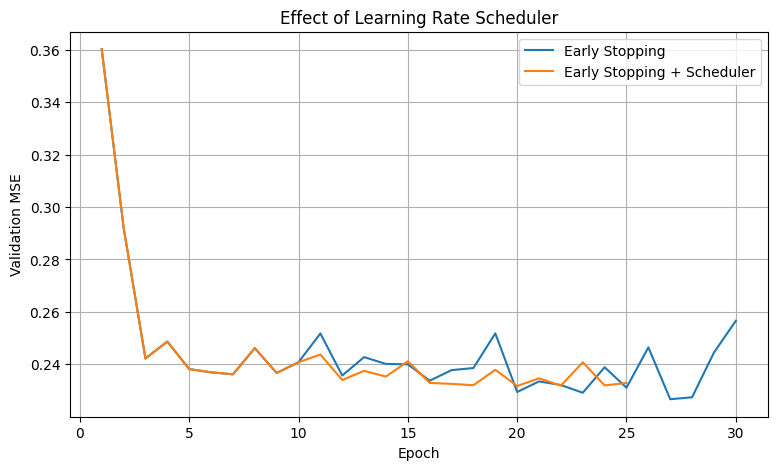

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(val_losses_early) + 1),
    val_losses_early,
    label="Early Stopping"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Early Stopping + Scheduler"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Effect of Learning Rate Scheduler")
plt.legend()
plt.grid(True)
plt.show()



### Learning Rate Scheduler Results

We compared two training strategies using the same CNN architecture and a fixed random seed.

| Configuration | Best Epoch | Best Validation MSE |
|---|---:|---:|
| Early Stopping | 27 | 0.2267 |
| Early Stopping + Scheduler | 20 | 0.2317 |

The scheduler successfully reduced the learning rate when validation performance stopped improving.

However, adding the scheduler did not improve the best validation MSE in this experiment.

The scheduler configuration may not be optimal, and a single run is insufficient to establish a general performance difference.

**Conclusion:** The scheduler worked as intended, but its benefit was not demonstrated for this CNN configuration.



## 6. Reusable Training Function

To avoid duplicating the training loop for each experiment, we define a reusable `train_model()` function.

The function supports:
- **Training and validation:** using MSELoss.
- **Early Stopping:** stops training when validation MSE does not improve.
- **Learning Rate Scheduler:** optionally adjusts the learning rate based on validation performance.
- **Best model restoration:** restores the weights from the epoch with the lowest validation MSE.
- **Training history:** records training MSE, validation MSE, and learning rate.

Regularization through Weight Decay is configured separately in the optimizer.

This function can be reused with different architectures, including the model selected from Milestone 3.


In [7]:

import copy

def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    device,
    epochs=30,
    patience=5,
    scheduler=None
):
    best_val_loss = float("inf")
    best_epoch = 0
    counter = 0
    best_model_state = None

    train_losses = []
    val_losses = []
    learning_rates = []
    stopped_early = False

    for epoch in range(epochs):

        # ===== TRAINING =====
        model.train()
        train_loss = 0.0

        current_lr = optimizer.param_groups[0]["lr"]
        learning_rates.append(current_lr)

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            predictions = model(images)
            loss = criterion(predictions, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

        train_loss /= len(train_loader.dataset)
        train_losses.append(train_loss)

        # ===== VALIDATION =====
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                predictions = model(images)
                loss = criterion(predictions, labels)

                val_loss += loss.item() * images.size(0)

        val_loss /= len(val_loader.dataset)
        val_losses.append(val_loss)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train MSE: {train_loss:.4f} | "
            f"Validation MSE: {val_loss:.4f} | "
            f"LR: {current_lr:.6f}"
        )

        # ===== SCHEDULER (OPTIONAL) =====
        if scheduler is not None:
            scheduler.step(val_loss)

        # ===== EARLY STOPPING =====
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            counter = 0
            best_model_state = copy.deepcopy(model.state_dict())
        else:
            counter += 1

        if patience is not None and counter >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            stopped_early = True
            break

    # Restore best model weights
    model.load_state_dict(best_model_state)

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation MSE: {best_val_loss:.4f}")

    return {
        "train_mse": train_losses,
        "val_mse": val_losses,
        "learning_rates": learning_rates,
        "best_epoch": best_epoch,
        "best_val_mse": best_val_loss,
        "epochs_run": len(train_losses),
        "stopped_early": stopped_early
    }



## 7. Combining Training Strategies

We now combine the three training strategies required in Milestone 4:

1. **Early Stopping:** stops training when validation performance no longer improves.
2. **Learning Rate Scheduler:** reduces the learning rate when validation MSE stagnates.
3. **Weight Decay:** regularizes model weights to help reduce overfitting.

We use AdamW with `weight_decay=1e-4` and keep the original SimpleCNN architecture.

The Early Stopping patience is increased to 8 to allow the scheduler more time to improve convergence after reducing the learning rate.

This experiment prepares the training strategy that will later be applied to the best architecture from Milestones 1–3.


In [8]:

# Set to True only when running this experiment
RUN_CNN_COMBINED = False

if RUN_CNN_COMBINED:

    # ===== REPRODUCIBILITY =====
    torch.manual_seed(42)

    model_combined = SimpleCNN().to(device)

    combined_train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=torch.Generator().manual_seed(42)
    )

    # ===== LOSS AND OPTIMIZER =====
    criterion = nn.MSELoss()

    optimizer = optim.AdamW(
        model_combined.parameters(),
        lr=0.001,
        weight_decay=1e-4
    )

    # ===== SCHEDULER =====
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )

    # ===== TRAINING =====
    history_combined = train_model(
        model=model_combined,
        train_loader=combined_train_loader,
        val_loader=val_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device,
        epochs=30,
        patience=8,
        scheduler=scheduler
    )


In [9]:

if RUN_CNN_COMBINED:

    plt.figure(figsize=(9, 5))

    plt.plot(
        history_combined["train_mse"],
        label="Training MSE"
    )

    plt.plot(
        history_combined["val_mse"],
        label="Validation MSE"
    )

    plt.xlabel("Epoch (starting at 0)")
    plt.ylabel("MSE")
    plt.title("CNN - Combined Training Strategies")
    plt.legend()
    plt.grid(True)
    plt.show()
